In [3]:
import numpy as np 
import pandas as pd 

import matplotlib.pyplot as plt 


In [4]:
df = pd.read_csv("TRAIN_1.csv", usecols= ["GarageQual", "FireplaceQu", "SalePrice"])
df.sample(5)

,FireplaceQu,GarageQual,SalePrice
160,NaN,TA,162500
19,NaN,TA,139000
340,NaN,TA,202900
603,NaN,TA,151000
890,Po,TA,122900


In [5]:
df.isnull().mean()*100

FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64

# Working With Pandas

## Applying Most Frequent Value Imputation on GarageQuality

Text(0, 0.5, 'Number of houses')

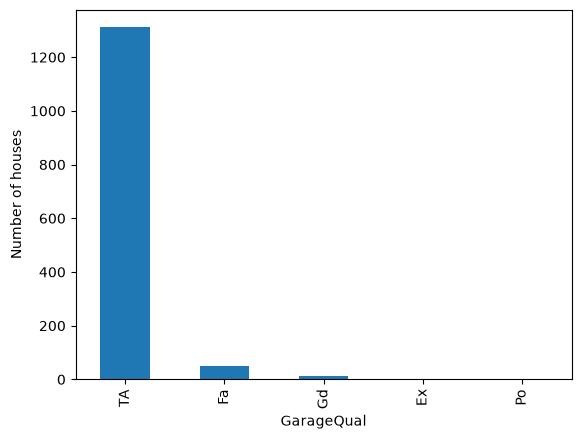

In [6]:
df["GarageQual"].value_counts().plot(kind= "bar")
plt.xlabel("GarageQual")
plt.ylabel("Number of houses")

In [7]:
df["GarageQual"].mode()

0    TA
Name: GarageQual, dtype: object

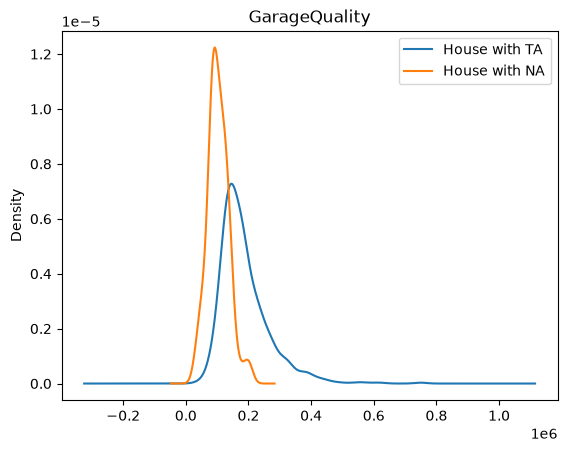

In [8]:
fig = plt.figure()
ax = fig.add_subplot(111)

df[df["GarageQual"] == "TA"]["SalePrice"].plot(kind= "kde", ax= ax, label= "House with TA")

df[df["GarageQual"].isnull()]["SalePrice"].plot(kind= "kde", ax= ax, label= "House with NA")
plt.legend()
plt.title("GarageQuality")
plt.show()

C:\Users\Asus\AppData\Local\Temp\ipykernel_20136\3984713290.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["GarageQual"].fillna("TA", inplace= True)


<Axes: xlabel='GarageQual'>

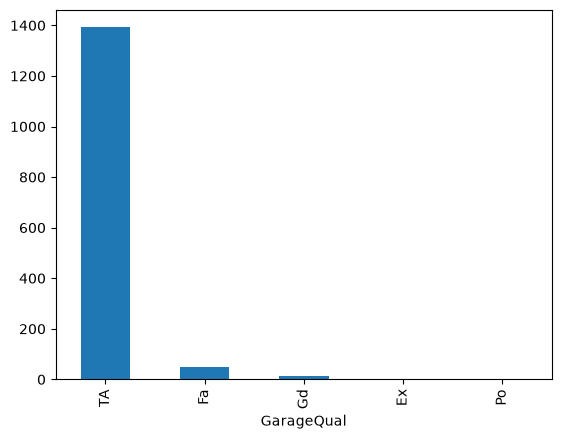

In [9]:
temp = df[df["GarageQual"] == "TA"]["SalePrice"]

df["GarageQual"].fillna("TA", inplace= True)
df["GarageQual"].value_counts().plot(kind= "bar")

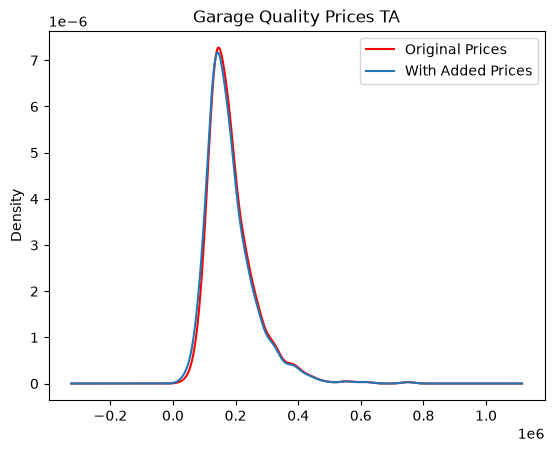

In [10]:

fig = plt.figure()
ax_1 = fig.add_subplot()

temp.plot(kind= "kde", ax= ax_1, label= "Original Prices", color= "Red") 
df[df["GarageQual"] == "TA"]["SalePrice"].plot(kind= "kde", ax= ax_1, label= "With Added Prices")

plt.legend()
plt.title("Garage Quality Prices TA")
plt.show()

## Applying Missing Category Imputation on FirplaceQaulity

In [11]:
df.isnull().mean()

FireplaceQu    0.472603
GarageQual     0.000000
SalePrice      0.000000
dtype: float64

<Axes: xlabel='FireplaceQu'>

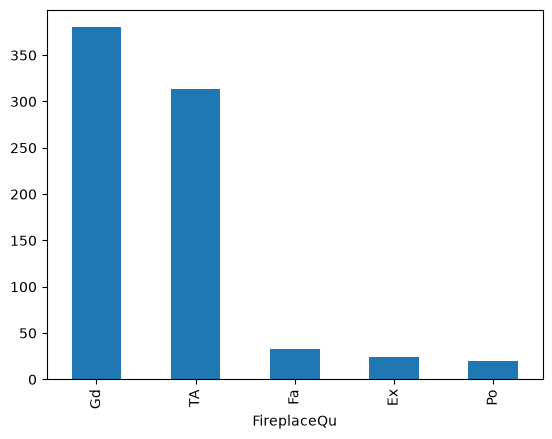

In [12]:
df["FireplaceQu"].value_counts().plot(kind= "bar")

In [13]:
df["FireplaceQu"].mode()

0    Gd
Name: FireplaceQu, dtype: object

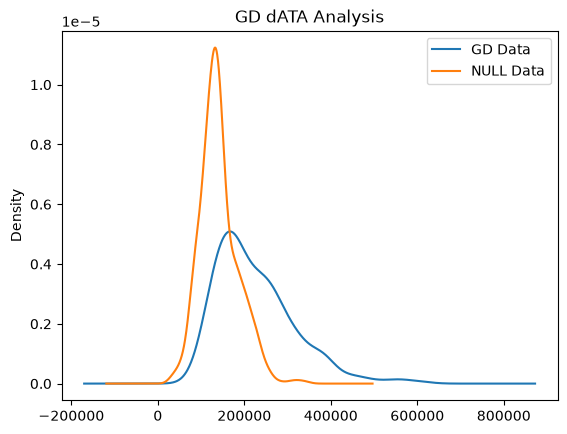

In [14]:
fig_2 = plt.figure()
ax_2 = fig_2.add_subplot() 

df[df["FireplaceQu"] == "Gd"]["SalePrice"].plot(kind= "kde", ax= ax_2, label= "GD Data")
df[df["FireplaceQu"].isnull()]["SalePrice"].plot(kind= "kde", ax= ax_2, label= "NULL Data")

plt.legend()
plt.title("GD dATA Analysis")
plt.show()

In [15]:
temp_2 = df[df["FireplaceQu"] == "Gd"]["SalePrice"]

In [16]:
df["FireplaceQu"].fillna("Gd", inplace= True)

GD_1 = df["FireplaceQu"].value_counts()["Gd"]

C:\Users\Asus\AppData\Local\Temp\ipykernel_20136\2030252254.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["FireplaceQu"].fillna("Gd", inplace= True)


In [17]:
print("New Gd Count: ", GD)

NameError: name 'GD' is not defined

<Axes: xlabel='FireplaceQu'>

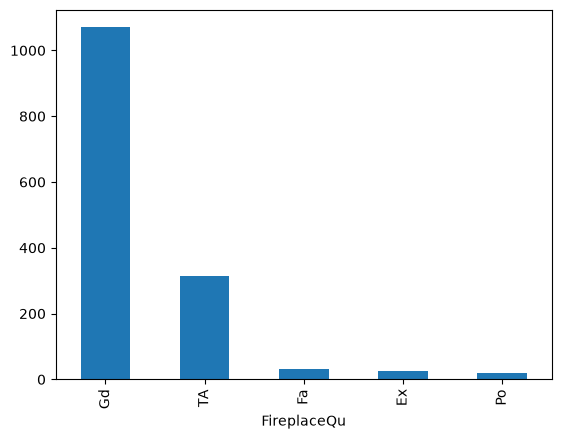

In [18]:
df["FireplaceQu"].value_counts().plot(kind= "bar")

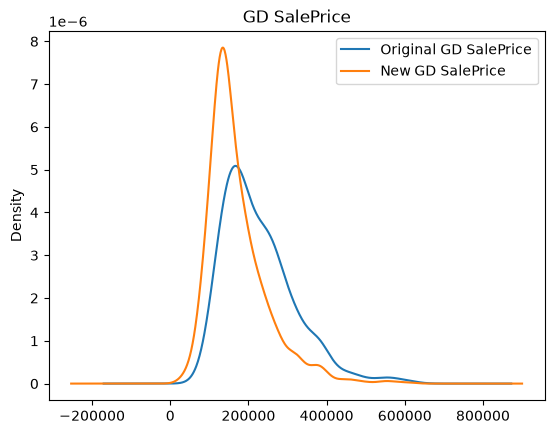

In [19]:
fig_3 = plt.figure()
ax_3 = fig_3.add_subplot()

temp_2.plot(kind= "kde", ax= ax_3, label= "Original GD SalePrice")
df[df["FireplaceQu"]== "Gd"]["SalePrice"].plot(kind= "kde", ax= ax_3, label= "New GD SalePrice")

plt.legend()
plt.title("GD SalePrice")
plt.show()

In [20]:
# Grapgh is not overlapping which is bad 
# So Most Frequent(Mode) is good for GarageQuality but not for FireplaceQuality

# Working With Sklearn

In [21]:
from sklearn.model_selection import train_test_split


In [22]:
x_train, x_test, y_train, y_test = train_test_split(
    df.drop(columns= ["SalePrice"]), 
    df["SalePrice"], 
    test_size= .2, 
    # random_state=
)

In [23]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy= "most_frequent")

In [24]:
x_train_imputer = imputer.fit_transform(x_train)
x_test_imputer = imputer.transform(x_test)

In [25]:
imputer.statistics_

array(['Gd', 'TA'], dtype=object)

# Missing Category Imputation

In [27]:
# In this method what we do is isntead of filling NA with mode we fill it with "Missing" text 
# So for that feature a new category "Missing" will be created

In [28]:

# And for SimpleImputer just do this step and rest is same 

# imputer = SimpleImputer(strategy= "constant". fill_value= "Missing")